# Pooling en el último bloque + logit lens antes/después del MLP (2026-10-17)

**Pregunta (de la conversación sobre `reward_similarity`):** si en el último bloque todas las cabezas miran lo mismo, ese bloque de atención se comporta como un *pooling* con un único mapa, y la decisión de clase tendría que tomarse después, en el MLP. ¿Es así?

Dos mediciones sobre los checkpoints ya entrenados (sin entrenar nada nuevo), con el **conjunto de test completo** (7468 imágenes; error estándar de la accuracy ≈ 0.5 puntos):

1. **Logit lens en cada punto del flujo residual**, separando lo que añade la atención de lo que añade el MLP en cada bloque: `embedding`, `b1 mid` (tras la atención del bloque 1, antes de su MLP), `b1 post`, …, `b4 post`. Dos lecturas:
   - *Lente del clasificador final* (logit lens clásico): se aplica el clasificador del modelo al CLS en ese punto. Puede subestimar, porque el clasificador solo se entrenó para la última capa.
   - *Probe lineal por punto* (validación cruzada de 3 pliegues sobre el CLS): mide cuánta información de clase es linealmente decodificable en ese punto, sin depender de la alineación con el clasificador.
2. **Intervención de pooling en la atención del último bloque** (solo cambia el mapa de atención; los valores, la proyección de salida y el MLP quedan igual):
   - `learned`: el modelo normal.
   - `shared_mean`: las 4 cabezas usan el promedio de sus 4 mapas de atención (un solo mapa compartido).
   - `uniform_patches`: promedio uniforme de los 64 parches (global average pooling, sin atención aprendida).

**Modelos:** `unconstrained`, `constrained`, `constrained_rank` y `reward_similarity` (`lambda_loss = -0.1`: se premia la similitud entre cabezas). Una semilla por variante.

In [1]:
import json
import math
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parents[1]
print(f"Project root: {project_root}")
sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from modules.model import ViTForClassfication
from modules.datasets import AwA2Dataset
from modules.figures import save_fig

torch.manual_seed(0)

EXPERIMENTS_DIR = project_root / "experimentation" / "experiments"
OUTPUT_DIR = EXPERIMENTS_DIR / "17102026_pooling_logit_lens"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "unconstrained": "vit-15-AwA2",
    "constrained": "vit-15-constrained-AwA2",
    "constrained_rank": "vit-15-constrained_rank-AwA2",
    "reward_similarity": "vit-15-reward_similarity-AwA2",
}
COLORS = {"unconstrained": "#4C78A8", "constrained": "#E45756", "constrained_rank": "#54A24B", "reward_similarity": "#B279A2"}

Project root: /Users/valefeve/Projects/interpretability of neural networks/interpretable-transformers


## 1. Modelos y test completo

In [2]:
def load_model(name):
    exp_dir = EXPERIMENTS_DIR / name
    with open(exp_dir / "config.json") as f:
        config = json.load(f)
    with open(exp_dir / "metrics.json") as f:
        metrics = json.load(f)
    model = ViTForClassfication(config)
    model.load_state_dict(torch.load(exp_dir / "model_final.pt", map_location="cpu"))
    model.eval()
    assert not config.get("use_faster_attention", False), "El notebook asume cabezas separadas (block.attention.heads)"
    return model, config, metrics

models = {key: load_model(name) for key, name in MODELS.items()}
config = models["unconstrained"][1]
assert all(m[1] == config for m in models.values()), "Los modelos deben tener la misma arquitectura"
n_blocks = len(models["unconstrained"][0].encoder.blocks)
for key, (_, _, metrics) in models.items():
    print(f"{key:>18} ({MODELS[key]}): accuracy en metrics.json = {metrics['accuracy']:.4f}")

dataset = AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2"))
_, _, classes = dataset.get_loaders(batch_size=256)   # inicializa dataset.testset
images, labels = dataset.get_samples_from_indices(list(range(len(dataset.testset))), device="cpu", set="test")
n = len(images)
print(f"Test completo: {n} imágenes, {dataset.n_classes} clases | error estándar de la accuracy ≈ {math.sqrt(0.3 * 0.7 / n):.4f}")

     unconstrained (vit-15-AwA2): accuracy en metrics.json = 0.2971
       constrained (vit-15-constrained-AwA2): accuracy en metrics.json = 0.2879
  constrained_rank (vit-15-constrained_rank-AwA2): accuracy en metrics.json = 0.2973
 reward_similarity (vit-15-reward_similarity-AwA2): accuracy en metrics.json = 0.2631


Test completo: 7468 imágenes, 50 clases | error estándar de la accuracy ≈ 0.0053


## 2. Funciones

`collect_points` corre el forward bloque a bloque y guarda el CLS en cada punto del flujo residual (pre-LN: `x = x + atención(LN(x))` y luego `x = x + MLP(LN(x))`). `last_block_forward` reimplementa el último bloque para poder cambiar el mapa de atención. Ambas se verifican contra el forward original.

In [3]:
@torch.no_grad()
def collect_points(model, x):
    points = {}
    h = model.embedding(x)
    points["embedding"] = h[:, 0]
    for b, blk in enumerate(model.encoder.blocks, start=1):
        a, _ = blk.attention(blk.layernorm_1(h))
        h = h + a
        points[f"b{b} mid"] = h[:, 0]
        h = h + blk.mlp(blk.layernorm_2(h))
        points[f"b{b} post"] = h[:, 0]
    return points


@torch.no_grad()
def last_block_forward(model, x, mode):
    h = model.embedding(x)
    blocks = model.encoder.blocks
    for blk in blocks[:-1]:
        h, _ = blk(h)
    blk = blocks[-1]
    z = blk.layernorm_1(h)
    probs, values = [], []
    for head in blk.attention.heads:
        q, k, v = head.query(z), head.key(z), head.value(z)
        probs.append(F.softmax(q @ k.transpose(-1, -2) / math.sqrt(head.attention_head_size), dim=-1))
        values.append(v)
    P = torch.stack(probs, dim=1)                          # (B, H, T, T)
    if mode == "learned":
        Pm = P
    elif mode == "shared_mean":
        Pm = P.mean(dim=1, keepdim=True).expand_as(P)
    elif mode == "uniform_patches":
        Pm = torch.zeros_like(P)
        Pm[..., 1:] = 1.0 / (P.shape[-1] - 1)              # el CLS reparte su atención entre los 64 parches
    else:
        raise ValueError(mode)
    heads_out = torch.cat([Pm[:, i] @ values[i] for i in range(len(values))], dim=-1)
    h = h + blk.attention.output_projection(heads_out)
    h = h + blk.mlp(blk.layernorm_2(h))
    return model.classifier(h[:, 0])


def batched(fn, x, bs=1000):
    return torch.cat([fn(x[i:i + bs]) for i in range(0, len(x), bs)])

# Verificaciones: las reimplementaciones deben reproducir el modelo
with torch.no_grad():
    for key, (model, _, _) in models.items():
        ref = model(images[:500])[0]
        d1 = (last_block_forward(model, images[:500], "learned") - ref).abs().max().item()
        d2 = (model.classifier(collect_points(model, images[:500])[f"b{n_blocks} post"]) - ref).abs().max().item()
        print(f"{key:>18}: |last_block - modelo| = {d1:.1e} | |puntos(b{n_blocks} post) - modelo| = {d2:.1e}")

     unconstrained: |last_block - modelo| = 0.0e+00 | |puntos(b4 post) - modelo| = 0.0e+00


       constrained: |last_block - modelo| = 0.0e+00 | |puntos(b4 post) - modelo| = 0.0e+00


  constrained_rank: |last_block - modelo| = 0.0e+00 | |puntos(b4 post) - modelo| = 0.0e+00


 reward_similarity: |last_block - modelo| = 0.0e+00 | |puntos(b4 post) - modelo| = 0.0e+00


## 3. Logit lens con el clasificador final, antes y después de cada MLP

In [4]:
POINTS = ["embedding"] + [f"b{b} {s}" for b in range(1, n_blocks + 1) for s in ("mid", "post")]

feats = {}      # key -> point -> (N, D)
lens_acc = {}
with torch.no_grad():
    for key, (model, _, _) in models.items():
        pts = {p: [] for p in POINTS}
        for i in range(0, n, 1000):
            out = collect_points(model, images[i:i + 1000])
            for p in POINTS:
                pts[p].append(out[p])
        feats[key] = {p: torch.cat(v) for p, v in pts.items()}
        lens_acc[key] = {p: (model.classifier(feats[key][p]).argmax(-1) == labels).float().mean().item() for p in POINTS}

lens_df = pd.DataFrame(lens_acc, index=POINTS)
print("Accuracy del logit lens (clasificador final aplicado al CLS en cada punto):")
print(lens_df.round(3).to_string())
lens_df.to_csv(OUTPUT_DIR / "logit_lens_mid_post.csv")

Accuracy del logit lens (clasificador final aplicado al CLS en cada punto):
           unconstrained  constrained  constrained_rank  reward_similarity
embedding          0.036        0.027             0.027              0.036
b1 mid             0.084        0.065             0.066              0.079
b1 post            0.059        0.048             0.062              0.075
b2 mid             0.088        0.065             0.106              0.138
b2 post            0.083        0.072             0.106              0.130
b3 mid             0.115        0.113             0.186              0.176
b3 post            0.142        0.124             0.196              0.199
b4 mid             0.249        0.237             0.284              0.228
b4 post            0.297        0.288             0.297              0.263


## 4. Probe lineal por punto (validación cruzada de 3 pliegues)

El logit lens clásico subestima los puntos intermedios porque el clasificador no está alineado con ellos. El probe ajusta un clasificador lineal propio en cada punto y mide cuánta información de clase hay disponible linealmente.

In [5]:
y = labels.numpy()
folds = list(StratifiedKFold(3, shuffle=True, random_state=0).split(np.zeros(n), y))
probe_acc = {}
for key in MODELS:
    probe_acc[key] = {}
    for p in POINTS:
        X = feats[key][p].numpy()
        pred = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=300)), X, y, cv=folds)
        probe_acc[key][p] = float((pred == y).mean())
    print(key, "listo")

probe_df = pd.DataFrame(probe_acc, index=POINTS)
print("\nAccuracy del probe lineal por punto:")
print(probe_df.round(3).to_string())
probe_df.to_csv(OUTPUT_DIR / "probe_mid_post.csv")

unconstrained listo


constrained listo


constrained_rank listo


reward_similarity listo

Accuracy del probe lineal por punto:
           unconstrained  constrained  constrained_rank  reward_similarity
embedding          0.044        0.044             0.044              0.044
b1 mid             0.236        0.235             0.235              0.244
b1 post            0.235        0.235             0.235              0.245
b2 mid             0.285        0.278             0.283              0.302
b2 post            0.285        0.277             0.282              0.302
b3 mid             0.323        0.328             0.325              0.337
b3 post            0.322        0.326             0.325              0.337
b4 mid             0.342        0.344             0.337              0.335
b4 post            0.339        0.343             0.337              0.340


## 5. Quién aporta qué: atención frente a MLP, bloque por bloque

Incremento de accuracy al pasar de un punto al siguiente: `atención = mid − post del bloque anterior`; `MLP = post − mid`. En el primer bloque la referencia es `embedding`. Se calcula con las dos lecturas.

Incrementos (lente del clasificador final):
             unconstrained  constrained  constrained_rank  reward_similarity
b1 atención          0.048        0.039             0.040              0.043
b1 MLP              -0.025       -0.017            -0.004             -0.004
b2 atención          0.030        0.017             0.044              0.064
b2 MLP              -0.005        0.007             0.001             -0.008
b3 atención          0.032        0.041             0.080              0.046
b3 MLP               0.026        0.010             0.010              0.023
b4 atención          0.107        0.113             0.087              0.029
b4 MLP               0.048        0.051             0.014              0.035

Incrementos (probe lineal):
             unconstrained  constrained  constrained_rank  reward_similarity
b1 atención          0.192        0.191             0.191              0.200
b1 MLP              -0.001       -0.000            -0.000              0.001
b2 

guardado: experimentation/experiments/17102026_pooling_logit_lens/lens_mid_post.png


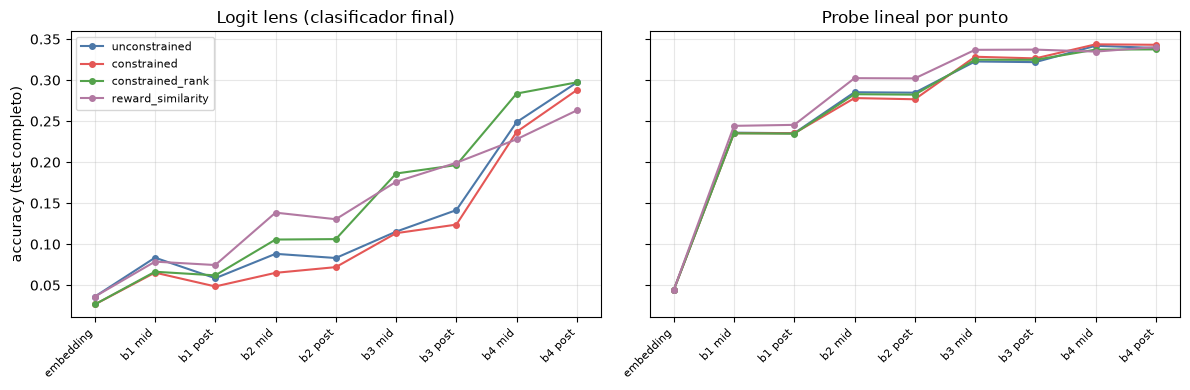

In [6]:
def increments(df):
    rows = {}
    prev = "embedding"
    for b in range(1, n_blocks + 1):
        rows[f"b{b} atención"] = df.loc[f"b{b} mid"] - df.loc[prev]
        rows[f"b{b} MLP"] = df.loc[f"b{b} post"] - df.loc[f"b{b} mid"]
        prev = f"b{b} post"
    return pd.DataFrame(rows).T

inc_lens, inc_probe = increments(lens_df), increments(probe_df)
print("Incrementos (lente del clasificador final):")
print(inc_lens.round(3).to_string())
print("\nIncrementos (probe lineal):")
print(inc_probe.round(3).to_string())
inc_lens.to_csv(OUTPUT_DIR / "increments_lens.csv")
inc_probe.to_csv(OUTPUT_DIR / "increments_probe.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, df, title in zip(axes, (lens_df, probe_df), ("Logit lens (clasificador final)", "Probe lineal por punto")):
    for key in MODELS:
        ax.plot(range(len(POINTS)), df[key].values, marker="o", ms=4, label=key, color=COLORS[key])
    ax.set_xticks(range(len(POINTS)))
    ax.set_xticklabels(POINTS, rotation=45, ha="right", fontsize=8)
    ax.set_title(title)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("accuracy (test completo)")
axes[0].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "lens_mid_post", OUTPUT_DIR, project_root=project_root)
plt.show()

## 6. Intervención de pooling en el último bloque

Solo cambia el mapa de atención de las 4 cabezas del último bloque; todo lo demás queda igual. Si el bloque ya se comporta como un pooling, `shared_mean` no debería costar nada; `uniform_patches` indica cuánto aporta la atención aprendida frente a promediar todos los parches.

                   learned  shared_mean  uniform_patches  Δ shared_mean  Δ uniform_patches
unconstrained       0.2971       0.2341           0.2314        -0.0631            -0.0657
constrained         0.2879       0.2242           0.2136        -0.0637            -0.0743
constrained_rank    0.2973       0.2236           0.2200        -0.0736            -0.0773
reward_similarity   0.2631       0.2634           0.2641         0.0003             0.0009
guardado: experimentation/experiments/17102026_pooling_logit_lens/pooling_last_block.png


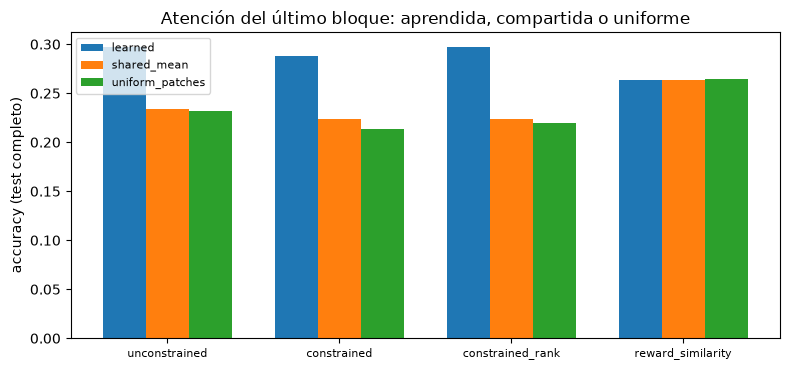

In [7]:
MODES = ["learned", "shared_mean", "uniform_patches"]
pool_acc = {}
with torch.no_grad():
    for key, (model, _, _) in models.items():
        pool_acc[key] = {m: (batched(lambda x: last_block_forward(model, x, m), images).argmax(-1) == labels).float().mean().item()
                         for m in MODES}
pool_df = pd.DataFrame(pool_acc, index=MODES).T
pool_df["Δ shared_mean"] = pool_df["shared_mean"] - pool_df["learned"]
pool_df["Δ uniform_patches"] = pool_df["uniform_patches"] - pool_df["learned"]
print(pool_df.round(4).to_string())
pool_df.to_csv(OUTPUT_DIR / "pooling_last_block.csv")

fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.25
for j, m in enumerate(MODES):
    ax.bar(np.arange(len(MODELS)) + (j - 1) * w, pool_df[m].values, w, label=m)
ax.set_xticks(range(len(MODELS)))
ax.set_xticklabels(list(MODELS), fontsize=8)
ax.set_ylabel("accuracy (test completo)")
ax.set_title("Atención del último bloque: aprendida, compartida o uniforme")
ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "pooling_last_block", OUTPUT_DIR, project_root=project_root)
plt.show()

## Cómo leer los resultados

- **Lente / probe en `b4 mid` frente a `b4 post`:** si la accuracy sube sobre todo al pasar por el MLP del bloque 4, la decisión se toma ahí; si ya está en `b4 mid`, la toma la atención. La comparación entre `reward_similarity` y `unconstrained` dice si colapsar las cabezas mueve la decisión hacia el MLP.
- **`shared_mean`:** en `reward_similarity` las cabezas ya comparten mapa, así que debería ser casi neutro. Una caída en el resto de modelos mide cuánto usaban mapas distintos.
- **Límites:** una semilla por variante; diferencias menores a ~1 punto (2 errores estándar) no son concluyentes. El logit lens en puntos intermedios depende de la alineación con el clasificador final (por eso se incluye el probe).